# Project — How Far Can You Push a Frozen Backbone?

**COMS4036A / COMS7050A Computer Vision**

Lab 3 fine-tuned an ImageNet ResNet-50 on Oxford Pets, a domain close to ImageNet, and Section 6 probed it layer by layer. This project asks what happens to that picture as the target domain moves away from natural photographs. We keep the backbone frozen, probe it at five depths, and compare against a random network and against full training.

The five domains, in the order we hypothesise they sit from ImageNet (a hypothesis, not a measured distance): **Oxford-IIIT Pets** (natural photographs), **GTSRB** (traffic signs), **RSI-CB256** (satellite tiles), **C-NMC Leukemia** (microscope cells), **Chest X-ray Pneumonia** (grayscale radiographs).

Four conditions, run on every dataset:

| | weights | what trains | credited to |
|---|---|---|---|
| `random_probe` | random | linear layer on frozen features at each depth | architecture alone |
| `imagenet_probe` | ImageNet-1K | linear layer on frozen features at each depth | architecture + pretraining |
| `random_full` | random | everything | learning from scratch |
| `imagenet_ft` | ImageNet-1K | everything, backbone at a tenth of the head's learning rate | + adapting the features |

Set **Runtime ▸ Change runtime type** to a GPU. Pets and GTSRB download on their own; C-NMC, RSI-CB256 and Chest X-ray come from Kaggle, so you need an API token. The full run takes roughly 45 to 90 minutes on a T4 with the default subsampling in Section 0.

In [ ]:
# Group members
MEMBERS = [
    # ("Student name", "Student number"),
    ("Mashego Mabeloane" , "2654606"),
    ("Basimane Ravele Lebopa", "2674912")
]
for name, number in MEMBERS:
    print(f"{number}  {name}")

2654606  Mashego Mabeloane
2674912  Basimane Ravele Lebopa


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 0. Setup, config, and logging

In [ ]:
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50

DEV = "cuda" if torch.cuda.is_available() else "cpu"


def seed_everything(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(0)
print("device:", DEV)

device: cuda


Everything you might want to change is in the next cell. The caps keep each dataset to a size where ten epochs take a few minutes; set them to `None` to train on everything. The three Kaggle datasets need the token below, and RSI-CB256 needs its slug (the cell after the config lists candidates).

In [ ]:
SEED = 0
DATASETS = ["pets", "gtsrb", "rsicb", "cnmc", "cxr"]  # hypothesised order of domain shift
TITLES = {"pets": "Oxford Pets", "gtsrb": "GTSRB", "rsicb": "RSI-CB256", "cnmc": "C-NMC", "cxr": "Chest X-ray"}
FLIP = {"pets": True, "gtsrb": False, "rsicb": True, "cnmc": True, "cxr": True}  # a flipped stop sign is not a stop sign

MAX_TRAIN, MAX_VAL, MAX_TEST = 4000, 1000, 2000
EPOCHS = 10
LR_HEAD, LR_BACKBONE = 1e-2, 1e-3  # as Lab 3 Section 5; random_full uses LR_HEAD for everything
CUTS = ["stem", "layer1", "layer2", "layer3", "layer4"]
PROBE_WDS = [0, 1e-4, 1e-3, 1e-2]  # probe weight decay, chosen on validation macro-F1

RSI_SLUG = None   # set automatically by the finder cell below

USE_WANDB = True

os.makedirs("results", exist_ok=True)

In [ ]:
if USE_WANDB:
    import wandb

    wandb.login()

Kaggle credentials: add `KAGGLE_USERNAME` and `KAGGLE_KEY` as Colab Secrets (the key icon in the left sidebar), or upload `kaggle.json` when asked.

In [ ]:

from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
print("using Colab secrets")


using Colab secrets


## 1. The data

Five directories of images and five different ways of saying which image is which. As in Lab 3, `__init__` reads the *list* of files and `__getitem__` reads the *image*, so nothing is held in memory but paths. One `ImageDataset` serves all five: each dataset gets a small function that turns its own layout into `(paths, labels)` for train, validation and test.

Three of these datasets contain many photographs of the same underlying thing, and a random split would put near-copies on both sides of the train/test line and flatter every number in the project. So the splits are made carefully:

- **GTSRB:** each physical sign is photographed about thirty times as a car approaches. The validation split is cut by *track* (the first number in the file name).
- **C-NMC:** many cells per patient. Split by patient (the second field of the file name).
- **Chest X-ray:** several radiographs per patient. Split by patient. The official validation folder holds only 16 images, so it is merged into train and re-split.
- **Pets, GTSRB:** the official test sets are used. **RSI-CB256** has no official split, so it gets a stratified random 70/10/20; neighbouring tiles can be near-duplicates, which is a caveat to state in the write-up.

In [ ]:
!wget -q -nc https://thor.robots.ox.ac.uk/pets/images.tar.gz
!wget -q -nc https://thor.robots.ox.ac.uk/pets/annotations.tar.gz
!tar -xzf images.tar.gz && tar -xzf annotations.tar.gz
!head -3 annotations/trainval.txt

Abyssinian_100 1 1 1
Abyssinian_101 1 1 1
Abyssinian_102 1 1 1


In [ ]:
!mkdir -p data
!([ -d data/cnmc ] || kaggle datasets download -q -d andrewmvd/leukemia-classification -p data/cnmc --unzip)
!([ -d data/cxr ] || kaggle datasets download -q -d paultimothymooney/chest-xray-pneumonia -p data/cxr --unzip)
!ls data/cnmc data/cxr

data/cnmc:
C-NMC_Leukemia

data/cxr:
chest_xray


RSI-CB256 is on Kaggle under several names. Run the search, choose the one with 35 class folders of 256×256 images, and put its slug in `RSI_SLUG` in the config cell (or upload the folder yourself and point `data/rsicb` at it).

In [ ]:
!kaggle datasets list -s RSI-CB256

ref                                           title                                  size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------  -------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
mahmoudreda55/satellite-image-classification  Satellite Image Classification     22836290  2021-08-21 18:13:09.973000          30285        216  0.8125           


In [ ]:
assert "REPLACE" not in RSI_SLUG, "set RSI_SLUG in the config cell"
!([ -d data/rsicb ] || kaggle datasets download -q -d {RSI_SLUG} -p data/rsicb --unzip)
!ls data/rsicb | head

Dataset URL: https://www.kaggle.com/datasets/mahmoudreda55/satellite-image-classification
License(s): copyright-authors
data


In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".tif", ".tiff"}


def scan(root, keep=lambda p: True):
    out = []
    for dirpath, _, files in os.walk(root):
        for f in files:
            p = os.path.join(dirpath, f)
            if os.path.splitext(f)[1].lower() in IMG_EXT and "__MACOSX" not in p and keep(p):
                out.append(p)
    return sorted(out)


def split_idx(idx, y, frac, groups=None):
    # returns (rest, held_out) index arrays; stratified, or grouped when groups is given
    idx, y = np.asarray(idx), np.asarray(y)
    if groups is None:
        return train_test_split(idx, test_size=frac, stratify=y[idx], random_state=SEED)
    a, b = next(GroupShuffleSplit(1, test_size=frac, random_state=SEED).split(idx, y[idx], np.asarray(groups)[idx]))
    return idx[a], idx[b]


def pack(paths, y, classes, tr, va, te):
    paths, y = np.asarray(paths), np.asarray(y)
    return {"train": (paths[tr], y[tr]), "val": (paths[va], y[va]), "test": (paths[te], y[te]), "classes": classes}


def subsample(paths, y, n):
    if n is None or len(paths) <= n:
        return paths, y
    keep, _ = train_test_split(np.arange(len(paths)), train_size=n, stratify=y, random_state=SEED)
    return paths[keep], y[keep]


def folder_labels(paths):
    names = sorted({os.path.basename(os.path.dirname(p)) for p in paths})
    return np.array([names.index(os.path.basename(os.path.dirname(p))) for p in paths]), names

Pets, the way Lab 3 parsed it: read the split files, take the stem and the class ID, strip the trailing number off the stem for the breed name.

In [ ]:
def build_pets():
    def read(name):
        stems, labels = [], []
        for line in open(f"annotations/{name}.txt"):
            stem, cid = line.split()[:2]
            stems.append(stem)
            labels.append(int(cid) - 1)
        return stems, labels

    tv_stems, tv_y = read("trainval")
    te_stems, te_y = read("test")
    classes = [None] * 37
    for s, y in zip(tv_stems + te_stems, tv_y + te_y):
        classes[y] = s.rsplit("_", 1)[0]
    paths = [f"images/{s}.jpg" for s in tv_stems + te_stems]
    y = tv_y + te_y
    n_tv = len(tv_stems)
    tr, va = split_idx(np.arange(n_tv), y, 0.15)
    return pack(paths, y, classes, tr, va, np.arange(n_tv, len(paths)))


def build_gtsrb():
    from torchvision.datasets import GTSRB

    tv = GTSRB("data", split="train", download=True)
    te = GTSRB("data", split="test", download=True)
    samples = tv._samples + te._samples
    paths = [s[0] for s in samples]
    y = [s[1] for s in samples]
    n_tv = len(tv._samples)
    tracks = [f"{y[i]}_{os.path.basename(paths[i]).split('_')[0]}" for i in range(n_tv)]
    tr, va = split_idx(np.arange(n_tv), y, 0.15, tracks + ["x"] * len(te._samples))
    return pack(paths, y, [str(i) for i in range(43)], tr, va, np.arange(n_tv, len(paths)))


def build_rsicb():
    paths = scan("data/rsicb")
    y, classes = folder_labels(paths)
    print("RSI-CB classes found:", len(classes), "(expected 35)")
    rest, te = split_idx(np.arange(len(paths)), y, 0.2)
    tr, va = split_idx(rest, y, 0.125)
    return pack(paths, y, classes, tr, va, te)


def build_cnmc():
    paths = scan("data/cnmc", keep=lambda p: "training_data" in p)  # only the labelled folds
    y, classes = folder_labels(paths)
    patients = [os.path.basename(p).split("_")[1] for p in paths]
    rest, te = split_idx(np.arange(len(paths)), y, 0.2, patients)
    tr, va = split_idx(rest, y, 0.125, patients)
    return pack(paths, y, classes, tr, va, te)


def build_cxr():
    seen, paths, where = set(), [], []
    for p in scan("data/cxr"):
        parts = p.split(os.sep)
        sp = next((s for s in ("train", "val", "test") if s in parts), None)
        key = (sp, os.path.basename(os.path.dirname(p)), os.path.basename(p))
        if sp is None or key in seen:  # the archive holds a nested duplicate copy
            continue
        seen.add(key)
        paths.append(p)
        where.append(sp)
    y, classes = folder_labels(paths)
    where = np.array(where)
    patients = [os.path.basename(p).split("_")[0] if os.path.basename(p).startswith("person")
                else os.path.basename(p).rsplit("-", 1)[0] for p in paths]
    tr, va = split_idx(np.where(where != "test")[0], y, 0.1, patients)
    return pack(paths, y, classes, tr, va, np.where(where == "test")[0])


BUILDERS = dict(pets=build_pets, gtsrb=build_gtsrb, rsicb=build_rsicb, cnmc=build_cnmc, cxr=build_cxr)

The dataset class itself. One detail beyond Lab 3: `img.draft` asks the JPEG decoder to decode at reduced size when the file is far larger than we need. Chest X-rays are over a thousand pixels on a side, and without it two CPU workers cannot keep the GPU fed. It does nothing for other formats.

In [ ]:
class ImageDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = [int(l) for l in labels]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img.draft("RGB", (320, 320))
        img = img.convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[i]

Build the splits for all five datasets (this downloads GTSRB, about 300 MB) and check them: sizes after subsampling, number of classes, and the smallest and largest class in the training split.

In [ ]:
SPLITS = {}
for name in DATASETS:
    s = BUILDERS[name]()
    for split, cap in [("train", MAX_TRAIN), ("val", MAX_VAL), ("test", MAX_TEST)]:
        s[split] = subsample(*s[split], cap)
    SPLITS[name] = s

rows = []
for name in DATASETS:
    s = SPLITS[name]
    counts = np.bincount(s["train"][1], minlength=len(s["classes"]))
    rows.append(dict(dataset=TITLES[name], train=len(s["train"][0]), val=len(s["val"][0]), test=len(s["test"][0]),
                     classes=len(s["classes"]), min_per_class=counts.min(), max_per_class=counts.max()))
pd.DataFrame(rows).set_index("dataset")

100%|██████████| 187M/187M [00:23<00:00, 8.13MB/s]
100%|██████████| 89.0M/89.0M [00:11<00:00, 7.70MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 211kB/s]


RSI-CB classes found: 4 (expected 35)


,train,val,test,classes,min_per_class,max_per_class
dataset,,,,,,
Oxford Pets,3128,552,2000,37,79,85
GTSRB,4000,1000,2000,43,21,239
RSI-CB256,3941,563,1127,4,791,1050
C-NMC,4000,1000,2000,2,1399,2601
Chest X-ray,4000,507,624,2,1021,2979


## 2. Transforms, and a look at what the network will see

Same two pipelines as Lab 3: an evaluation pipeline (resize the short side to 256, centre crop 224, ImageNet normalisation) and a training pipeline that adds a random resized crop and, where it is safe, a horizontal flip. ImageNet's statistics are used for every dataset, including the X-rays, because that is what the pretrained weights were fitted against, and the random-weight control uses the same inputs so the two are comparable.

The evaluation crop is square, so the long sides of non-square images (X-rays in particular) lose their edges. That is a choice we make and report, not a neutral one.

In [ ]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def make_loaders(splits, flip):
    norm = transforms.Normalize(MEAN, STD)
    eval_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(), norm])
    aug = [transforms.RandomResizedCrop(224, scale=(0.6, 1.0))]
    if flip:
        aug.append(transforms.RandomHorizontalFlip())
    train_tf = transforms.Compose(aug + [transforms.ToTensor(), norm])

    sets = {
        "train": ImageDataset(*splits["train"], train_tf),
        "train_eval": ImageDataset(*splits["train"], eval_tf),  # for features: same image, same feature, every time
        "val": ImageDataset(*splits["val"], eval_tf),
        "test": ImageDataset(*splits["test"], eval_tf),
    }
    return {k: DataLoader(v, batch_size=32 if k == "train" else 64, shuffle=(k == "train"),
                          drop_last=(k == "train"), num_workers=2) for k, v in sets.items()}

Before training on any of it: one training batch per dataset, un-normalised for display. Run it twice; the crops should differ. If a crop has lost the object, or the colours are wrong, find out now.

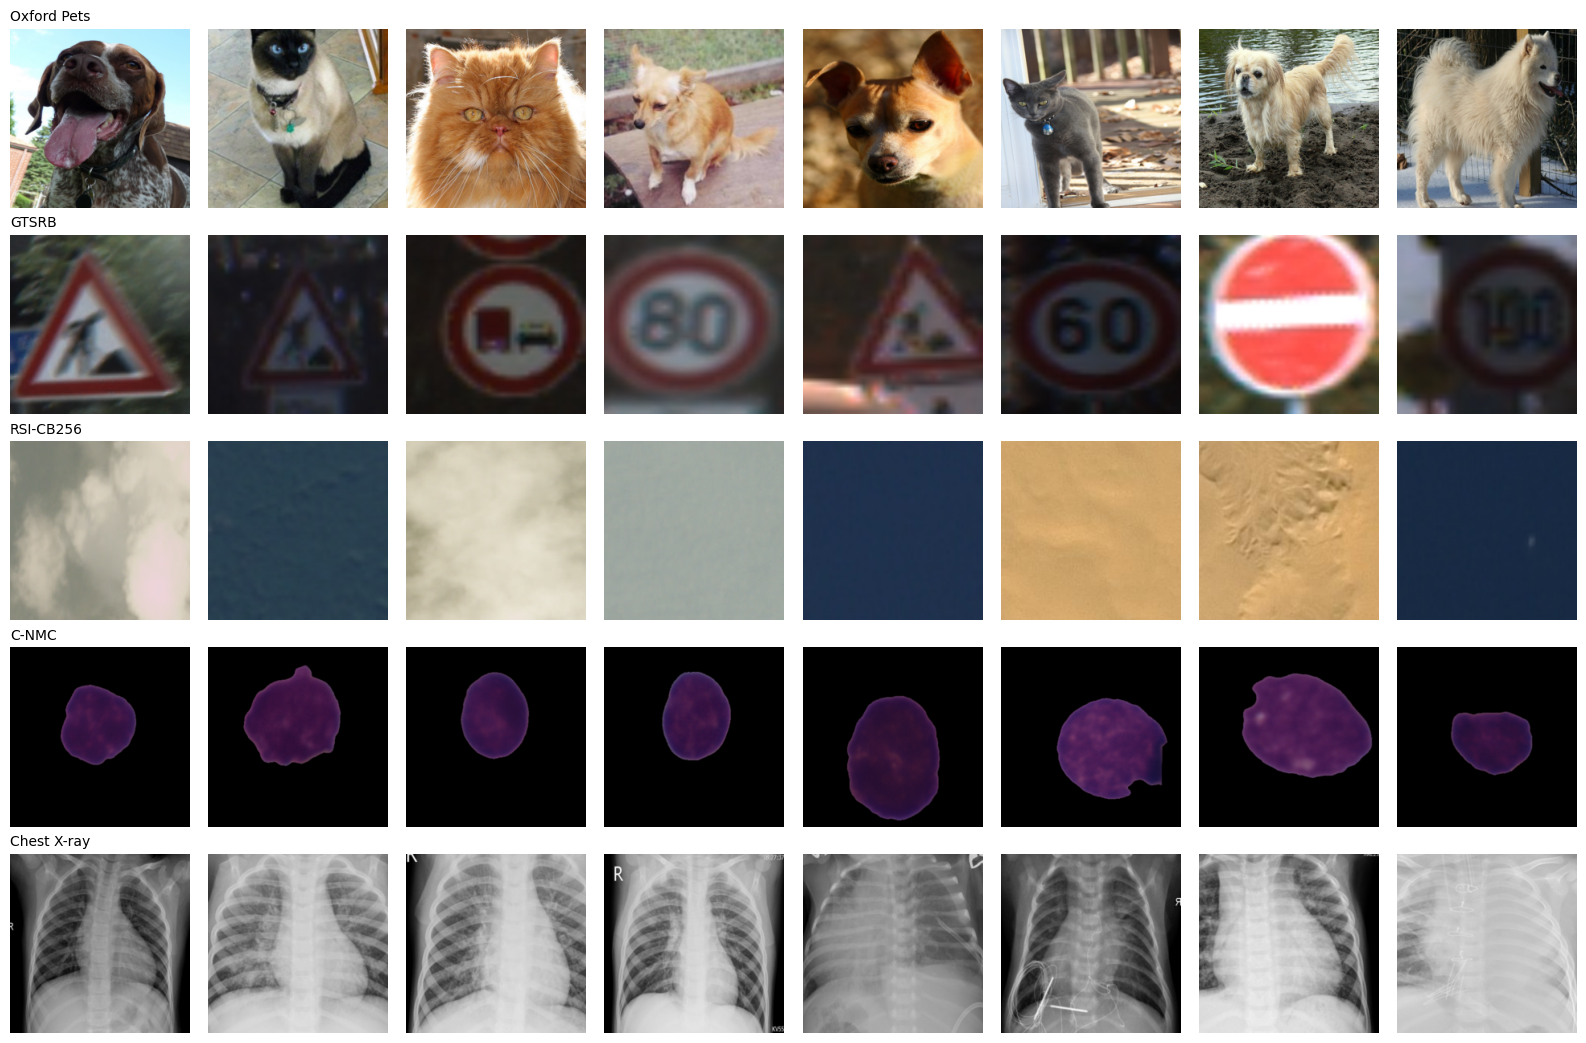

In [ ]:
def show_batch(loader, ax_row, n=8):
    x, y = next(iter(loader))
    x = (x[:n] * torch.tensor(STD).view(1, 3, 1, 1) + torch.tensor(MEAN).view(1, 3, 1, 1)).clamp(0, 1)
    for ax, img in zip(ax_row, x):
        ax.imshow(img.permute(1, 2, 0))
        ax.axis("off")


fig, axes = plt.subplots(len(DATASETS), 8, figsize=(16, 2.1 * len(DATASETS)))
for ax_row, name in zip(axes, DATASETS):
    show_batch(make_loaders(SPLITS[name], FLIP[name])["train"], ax_row)
    ax_row[0].set_title(TITLES[name], loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 3. The models

`make_model(pretrained, n_classes)` returns a ResNet-50 with a fresh `fc`. With `pretrained=True` the rest is ImageNet-1K; with `False` it is the same architecture at random initialisation. Both are used in two ways: as a frozen feature extractor (Section 4, where `fc` is ignored) and as a network trained end to end (Section 5).

In [ ]:
def make_model(pretrained, n_classes):
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc = nn.Linear(2048, n_classes)
    return model


m = make_model(True, 10)
print(f"{sum(p.numel() for p in m.parameters()):,} parameters")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 183MB/s]


23,528,522 parameters


## 4. Linear probes at five depths

`extract_features` runs the frozen backbone once and returns the globally average-pooled activations at five cuts: the **stem** (conv1, batch norm, ReLU and max-pool, 64 channels) and the outputs of `layer1` to `layer4` (256, 512, 1024, 2048 channels). All five come from a single pass, since the images, not the arithmetic, are the slow part. The backbone is in `eval()` mode throughout, so batch norm uses its stored statistics; for the random network those are the initial ones (mean 0, variance 1).

One thing to keep in mind when reading the curves: the feature dimension grows with depth, from 64 to 2048, so a probe at `layer4` has more parameters to fit than one at the stem. Part of any depth trend is dimension, not representation quality.

In [ ]:
@torch.no_grad()
def extract_features(model, loader):
    model.eval().to(DEV)
    feats = {c: [] for c in CUTS}
    labels = []
    for x, y in loader:
        x = x.to(DEV)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEV == "cuda"):
            h = model.maxpool(model.relu(model.bn1(model.conv1(x))))
            out = {"stem": h}
            h = model.layer1(h)
            out["layer1"] = h
            h = model.layer2(h)
            out["layer2"] = h
            h = model.layer3(h)
            out["layer3"] = h
            h = model.layer4(h)
            out["layer4"] = h
        for c in CUTS:
            feats[c].append(out[c].float().mean((2, 3)).cpu())
        labels.append(y)
    return {c: torch.cat(v) for c, v in feats.items()}, torch.cat(labels)

`fit_probe` standardises the features with the training set's mean and standard deviation and fits one `nn.Linear` with Adam for a hundred passes over the cached features. The weight decay is picked from `PROBE_WDS` on **validation** macro-F1; the test set is touched once, for the chosen value. Macro-F1 is reported next to accuracy because Chest X-ray and C-NMC are class-imbalanced, and accuracy alone rewards predicting the majority class.

In [ ]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


def fit_probe(train, val, test, n_classes, epochs=100):
    (ftr, ytr), (fva, yva), (fte, yte) = [(f.to(DEV), y.to(DEV)) for f, y in (train, val, test)]
    mu, sd = ftr.mean(0, keepdim=True), ftr.std(0, keepdim=True) + 1e-6
    ftr, fva, fte = (ftr - mu) / sd, (fva - mu) / sd, (fte - mu) / sd

    best = None
    for wd in PROBE_WDS:
        seed_everything(SEED)
        lin = nn.Linear(ftr.shape[1], n_classes).to(DEV)
        opt = torch.optim.Adam(lin.parameters(), lr=1e-3, weight_decay=wd)
        for _ in range(epochs):
            perm = torch.randperm(len(ftr), device=DEV)
            for i in range(0, len(ftr), 256):
                idx = perm[i:i + 256]
                loss = F.cross_entropy(lin(ftr[idx]), ytr[idx])
                opt.zero_grad()
                loss.backward()
                opt.step()
        with torch.no_grad():
            va_pred = lin(fva).argmax(1).cpu().numpy()
            va_f1 = macro_f1(yva.cpu().numpy(), va_pred)
            if best is None or va_f1 > best["val_f1"]:
                te_pred = lin(fte).argmax(1).cpu().numpy()
                best = dict(val_f1=va_f1, test_acc=float((te_pred == yte.cpu().numpy()).mean()),
                            test_f1=macro_f1(yte.cpu().numpy(), te_pred), wd=wd)
    return best

## 5. Training end to end

`evaluate` and `train` follow Lab 3, with three differences: `evaluate` also returns macro-F1, `train` takes the dictionary of loaders from Section 2, and it keeps the weights from the epoch with the best **validation** macro-F1 and reports the test score for those weights, so no epoch is chosen by looking at the test set.

`make_optimizer` uses the Lab 3 recipe: SGD with momentum 0.9 and weight decay $10^{-4}$, two parameter groups. For `imagenet_ft` the backbone gets a tenth of the head's learning rate, because the pretrained weights are already somewhere good and Lab 3's Q5.2 showed what a large step does to them. For `random_full` there is nothing to protect, so the whole network uses the head's rate.

In [ ]:
def evaluate(model, loader):
    model.eval()
    total, preds, ys = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEV), y.to(DEV)
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEV == "cuda"):
                out = model(x)
            total += F.cross_entropy(out.float(), y, reduction="sum").item()
            preds.append(out.argmax(1).cpu())
            ys.append(y.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return total / len(ys), float((preds == ys).mean()), macro_f1(ys, preds)


def make_optimizer(model, pretrained):
    backbone = [p for n, p in model.named_parameters() if not n.startswith("fc.")]
    lr_backbone = LR_BACKBONE if pretrained else LR_HEAD
    return torch.optim.SGD([{"params": backbone, "lr": lr_backbone},
                            {"params": model.fc.parameters(), "lr": LR_HEAD}],
                           momentum=0.9, weight_decay=1e-4)


def train(model, epochs, opt, run_name, config, loaders):
    if USE_WANDB:
        wandb.init(project="cv-project", name=run_name, config=config, reinit=True)
    scaler = torch.amp.GradScaler(enabled=DEV == "cuda")
    history, best_f1, best_state = [], -1, None
    for ep in range(epochs):
        model.train()
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in loaders["train"]:
            x, y = x.to(DEV), y.to(DEV)
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEV == "cuda"):
                out = model(x)
                loss = F.cross_entropy(out.float(), y)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        va_loss, va_acc, va_f1 = evaluate(model, loaders["val"])
        rec = {"epoch": ep + 1, "train/loss": tot_loss / n, "train/acc": correct / n,
               "val/loss": va_loss, "val/acc": va_acc, "val/f1": va_f1}
        history.append(rec)
        if USE_WANDB:
            wandb.log(rec)
        print(f"  ep {ep + 1:2d}  train {rec['train/loss']:.3f} / {rec['train/acc']:.3f}   "
              f"val {va_loss:.3f} / {va_acc:.3f}   val F1 {va_f1:.3f}")
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    _, va_acc, va_f1 = evaluate(model, loaders["val"])
    _, te_acc, te_f1 = evaluate(model, loaders["test"])
    if USE_WANDB:
        wandb.summary.update({"test/acc": te_acc, "test/f1": te_f1})
        wandb.finish()
    return history, dict(val_f1=va_f1, test_acc=te_acc, test_f1=te_f1)

## 6. Run the four conditions on every dataset

For each dataset: build the loaders, probe the random and the ImageNet backbone at all five cuts, then train `random_full` and `imagenet_ft` for `EPOCHS` epochs. Every run is seeded and named `{dataset}-{condition}` in W&B with its full config. Results are saved to `results/results.csv` after each dataset, so if Colab disconnects, re-run this cell and it carries on from where it stopped.

In [ ]:
RES_FILE = "results/results.csv"
results = pd.read_csv(RES_FILE).to_dict("records") if os.path.exists(RES_FILE) else []
done = {r["dataset"] for r in results}


def run_dataset(name):
    splits = SPLITS[name]
    n_classes = len(splits["classes"])
    loaders = make_loaders(splits, FLIP[name])
    new = []

    for cond, pretrained in [("random_probe", False), ("imagenet_probe", True)]:
        seed_everything(SEED)
        model = make_model(pretrained, n_classes)
        feats, labels = {}, {}
        for split, key in [("train", "train_eval"), ("val", "val"), ("test", "test")]:
            feats[split], labels[split] = extract_features(model, loaders[key])
        for cut in CUTS:
            r = fit_probe(*[(feats[s][cut], labels[s]) for s in ("train", "val", "test")], n_classes)
            new.append(dict(dataset=name, condition=cond, layer=cut, **r))
            print(f"  {cond:15s} {cut:7s} dim {feats['train'][cut].shape[1]:4d}   "
                  f"test acc {r['test_acc']:.3f}   F1 {r['test_f1']:.3f}")
        del model, feats

    for cond, pretrained in [("random_full", False), ("imagenet_ft", True)]:
        print(f"  -- {cond}")
        seed_everything(SEED)
        model = make_model(pretrained, n_classes).to(DEV)
        opt = make_optimizer(model, pretrained)
        config = dict(dataset=name, recipe=cond, pretrained=pretrained, epochs=EPOCHS, seed=SEED,
                      lr_head=LR_HEAD, lr_backbone=LR_BACKBONE if pretrained else LR_HEAD,
                      train_size=len(splits["train"][0]),
                      trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad))
        _, r = train(model, EPOCHS, opt, f"{name}-{cond}", config, loaders)
        new.append(dict(dataset=name, condition=cond, layer="all", **r))
        print(f"  {cond}: test acc {r['test_acc']:.3f}   F1 {r['test_f1']:.3f}")
        del model, opt
        torch.cuda.empty_cache()
    return new


for name in DATASETS:
    if name in done:
        print(f"== {TITLES[name]}: already done")
        continue
    t0 = time.time()
    print(f"\n===== {TITLES[name]} =====")
    results += run_dataset(name)
    pd.DataFrame(results).to_csv(RES_FILE, index=False)
    print(f"{TITLES[name]} finished in {(time.time() - t0) / 60:.1f} min")


===== Oxford Pets =====
  random_probe    stem    dim   64   test acc 0.099   F1 0.085
  random_probe    layer1  dim  256   test acc 0.155   F1 0.150
  random_probe    layer2  dim  512   test acc 0.145   F1 0.143
  random_probe    layer3  dim 1024   test acc 0.117   F1 0.116
  random_probe    layer4  dim 2048   test acc 0.103   F1 0.103
  imagenet_probe  stem    dim   64   test acc 0.122   F1 0.113
  imagenet_probe  layer1  dim  256   test acc 0.312   F1 0.307
  imagenet_probe  layer2  dim  512   test acc 0.465   F1 0.461
  imagenet_probe  layer3  dim 1024   test acc 0.778   F1 0.778
  imagenet_probe  layer4  dim 2048   test acc 0.917   F1 0.916
  -- random_full
  ep  1  train 4.487 / 0.031   val 3.699 / 0.027   val F1 0.001
  ep  2  train 3.808 / 0.034   val 3.582 / 0.043   val F1 0.007
  ep  3  train 3.655 / 0.042   val 3.531 / 0.054   val F1 0.010
  ep  4  train 3.592 / 0.048   val 3.486 / 0.053   val F1 0.024
  ep  5  train 3.498 / 0.062   val 3.463 / 0.082   val F1 0.035
  ep  6 

## 7. Results

**Q7.1.** Depth-performance curves, one panel per dataset: test macro-F1 against cut for the random and the ImageNet probe, with the two end-to-end results as horizontal dashed lines. (Accuracy is saved in the same dataframe if you want it.)

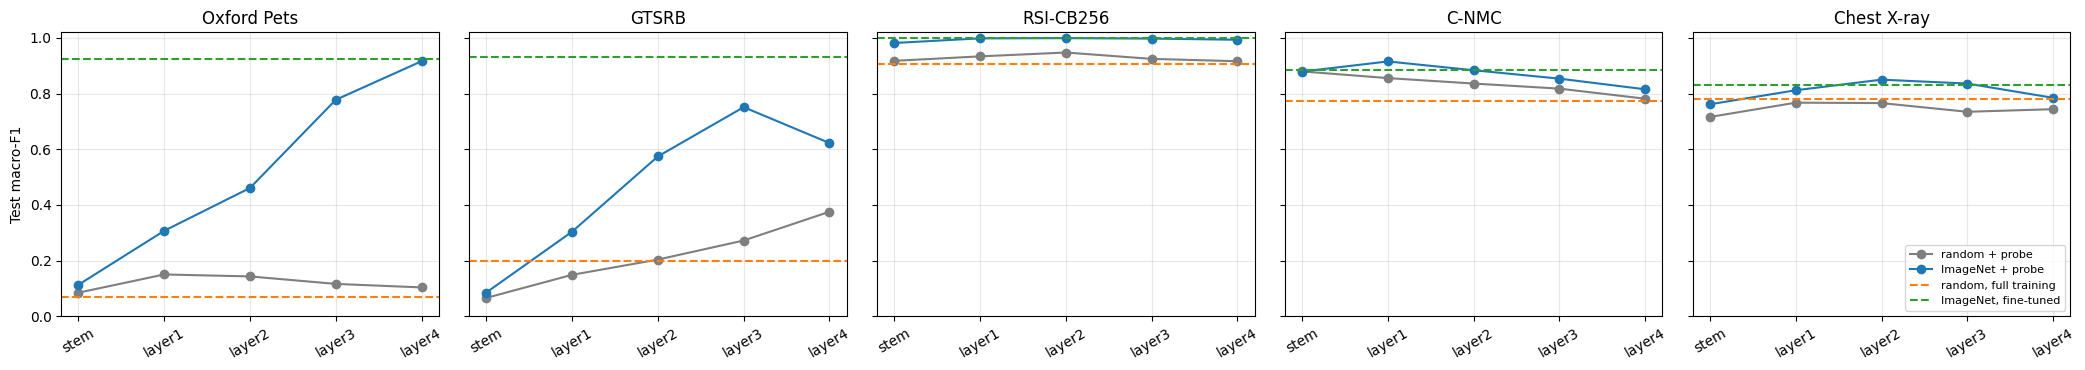

In [ ]:
df = pd.read_csv(RES_FILE)


def plot_depth_curves(df, metric="test_f1", ylabel="Test macro-F1"):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.2 * len(DATASETS), 3.8), sharey=True)
    for ax, name in zip(axes, DATASETS):
        sub = df[df.dataset == name]
        for cond, label, color in [("random_probe", "random + probe", "tab:gray"),
                                   ("imagenet_probe", "ImageNet + probe", "tab:blue")]:
            s = sub[sub.condition == cond].set_index("layer").loc[CUTS]
            ax.plot(CUTS, s[metric], marker="o", color=color, label=label)
        for cond, label, color in [("random_full", "random, full training", "tab:orange"),
                                   ("imagenet_ft", "ImageNet, fine-tuned", "tab:green")]:
            ax.axhline(sub[sub.condition == cond][metric].iloc[0], ls="--", color=color, label=label)
        ax.set_title(TITLES[name])
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)
        ax.tick_params(axis="x", rotation=30)
    axes[0].set_ylabel(ylabel)
    axes[-1].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()


plot_depth_curves(df)

**Q7.2.** For each dataset, which cut is best for the ImageNet probe (chosen on **validation** F1, so the choice does not peek at test), and what does it score? Report the same for the random probe, and the gap between the two best cuts. The table also lists both end-to-end results and what fine-tuning gains over training from scratch.

In [ ]:
rows = []
for name in DATASETS:
    sub = df[df.dataset == name]
    rec = {"dataset": TITLES[name]}
    for cond, tag in [("imagenet_probe", "imagenet"), ("random_probe", "random")]:
        s = sub[sub.condition == cond].set_index("layer").loc[CUTS]
        peak = s["val_f1"].idxmax()
        rec[f"{tag}_peak"] = peak
        rec[f"{tag}_F1"] = s.loc[peak, "test_f1"]
    rec["probe_gap"] = rec["imagenet_F1"] - rec["random_F1"]
    rec["scratch_F1"] = sub[sub.condition == "random_full"].test_f1.iloc[0]
    rec["finetune_F1"] = sub[sub.condition == "imagenet_ft"].test_f1.iloc[0]
    rec["finetune_gain"] = rec["finetune_F1"] - rec["scratch_F1"]
    rows.append(rec)
summary = pd.DataFrame(rows).set_index("dataset")
summary.to_csv("results/summary.csv")
summary.round(3)

,imagenet_peak,imagenet_F1,random_peak,random_F1,probe_gap,scratch_F1,finetune_F1,finetune_gain
dataset,,,,,,,,
Oxford Pets,layer4,0.916,layer1,0.150,0.766,0.069,0.925,0.856
GTSRB,layer3,0.751,layer4,0.375,0.376,0.200,0.931,0.731
RSI-CB256,layer1,0.998,layer2,0.947,0.051,0.908,1.000,0.092
C-NMC,layer1,0.915,stem,0.880,0.036,0.774,0.883,0.109
Chest X-ray,layer2,0.850,layer2,0.766,0.084,0.782,0.831,0.049


**Q7.3.** How much does pretraining help at each depth? Plot (ImageNet probe − random probe) test macro-F1 against cut, one line per dataset, and beside it the two summary gaps per dataset (best-cut probe gap, and fine-tune-minus-scratch).

layer         stem  layer1  layer2  layer3  layer4
Oxford Pets  0.028   0.157   0.318   0.662   0.813
GTSRB        0.019   0.155   0.371   0.479   0.247
RSI-CB256    0.064   0.065   0.052   0.073   0.077
C-NMC       -0.000   0.060   0.048   0.036   0.034
Chest X-ray  0.046   0.045   0.084   0.101   0.041


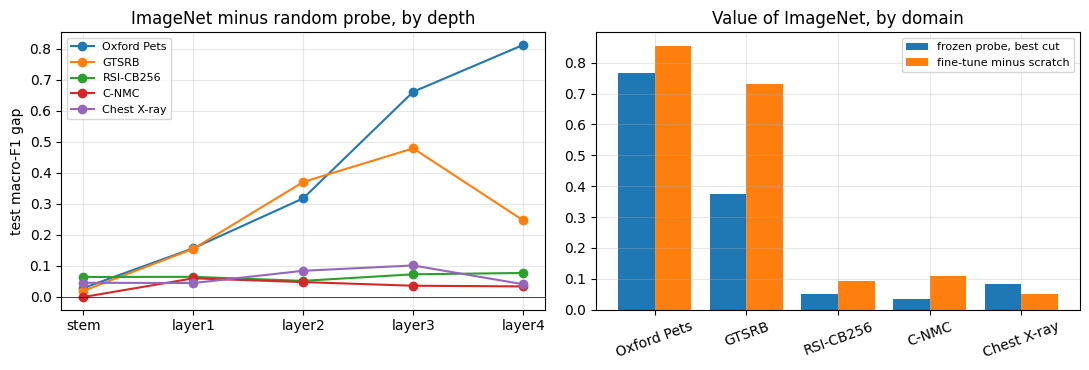

In [ ]:
f1 = df.pivot_table(index=["dataset", "condition"], columns="layer", values="test_f1")
gap = (f1.xs("imagenet_probe", level="condition") - f1.xs("random_probe", level="condition"))[CUTS].loc[DATASETS]
gap.index = [TITLES[d] for d in gap.index]
print(gap.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in DATASETS:
    axes[0].plot(CUTS, gap.loc[TITLES[name]], marker="o", label=TITLES[name])
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_title("ImageNet minus random probe, by depth")
axes[0].set_ylabel("test macro-F1 gap")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

x = np.arange(len(DATASETS))
axes[1].bar(x - 0.2, summary["probe_gap"], 0.4, label="frozen probe, best cut")
axes[1].bar(x + 0.2, summary["finetune_gain"], 0.4, label="fine-tune minus scratch")
axes[1].set_xticks(x)
axes[1].set_xticklabels(summary.index, rotation=20)
axes[1].set_title("Value of ImageNet, by domain")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()